# Phase 2 — Machine Learning
## Lesson 2.1.2: Understand Supervised vs. Unsupervised Learning

**Series:** AI & ML — Learn • Build • Grow  
**Module:** 2.1 — ML Fundamentals  
**Primary framework:** PyTorch  
**Environment:** Jupyter Notebook · CPU only

---

### What is the question of this lesson?

Imagine that we have information about customers: how often they visit a website and how much they spend.

There are two different questions we might ask:

1. **Supervised learning:** If we already know the category for each past customer, can a model learn to predict the category of a new customer?
2. **Unsupervised learning:** If we do not have categories, can an algorithm discover groups of customers with similar behavior?

The data can look similar, but the learning setup and goal are different.

### Learning objectives

By the end of this notebook, you should be able to:

- explain the role of known labels in supervised learning;
- explain why unsupervised learning uses examples without supplied target labels;
- distinguish classification from clustering;
- train a tiny PyTorch classifier with labeled examples;
- run a simple K-means clustering algorithm using PyTorch tensor operations;
- explain why cluster IDs do not automatically have a business meaning.

> **Scope:** This is a conceptual comparison with two small demonstrations. We will study features, targets, data splits, generalization, and full ML pipelines in later lessons. The synthetic data are for teaching—not real customer analytics.

## 1. Start with one dataset and two different questions

We will create a small synthetic dataset with two scores:

- **Monthly visit score:** a score from 0 to 10 representing how frequently a customer visits.
- **Spending score:** a score from 0 to 10 representing the customer's spending level.

For the supervised example, each customer also has a known category. We will use three simple teaching categories: `Occasional`, `Regular`, and `High-value`.

For the unsupervised example, we will deliberately hide those categories from the clustering algorithm. It will receive only the two numeric scores.

This is an important experiment: **same observations, different information provided to the learning method, different task.**

## 2. Import the libraries and set reproducible seeds

We use PyTorch for both demonstrations. The supervised classifier is a small neural-network model. The unsupervised K-means example is implemented with PyTorch tensor operations so you can see the clustering steps rather than calling a black-box function.

In [3]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

# Keep this introductory lesson reproducible and CPU-friendly.
torch.manual_seed(21)
np.random.seed(21)
device = torch.device("cpu")

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Occasional", "Regular", "High-value"]
CLASS_COLORS = ["#38BDF8", "#F59E0B", "#A78BFA"]
NEUTRAL_COLOR = "#94A3B8"

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

PyTorch version: 2.15.0+cpu
Device: cpu


## 3. Create the synthetic customer dataset

We generate three broad patterns so that the examples are easy to visualize. The category names are known in this synthetic supervised dataset. In real projects, known labels must come from an appropriate source—for example, human review or an existing business definition.

For this lesson, both features use the same 0–10 score scale. That keeps the distance-based clustering demonstration easy to interpret.

In [4]:
# Each row represents one customer. Both features use a 0–10 teaching scale.
centers = torch.tensor(
    [
        [2.0, 2.0],   # Occasional: lower visit and spending scores
        [7.5, 2.7],   # Regular: frequent visits, lower spending score
        [6.2, 7.5],   # High-value: frequent visits and higher spending score
    ],
    dtype=torch.float32,
)

samples_per_group = 60
feature_noise = torch.tensor([0.65, 0.70], dtype=torch.float32)

feature_parts = []
label_parts = []
for class_id, center in enumerate(centers):
    points = center + torch.randn(samples_per_group, 2) * feature_noise
    points = points.clamp(0.0, 10.0)
    feature_parts.append(points)
    label_parts.append(torch.full((samples_per_group,), class_id, dtype=torch.long))

X = torch.cat(feature_parts, dim=0).to(device)
y = torch.cat(label_parts, dim=0).to(device)

print(f"Number of customers: {X.shape[0]}")
print(f"Number of input features: {X.shape[1]}")
print(f"Known categories: {len(CLASS_NAMES)}")
print(f"X shape: {tuple(X.shape)}")
print(f"y shape: {tuple(y.shape)}")

Number of customers: 180
Number of input features: 2
Known categories: 3
X shape: (180, 2)
y shape: (180,)


## 4. Look at the same observations with and without category labels

First, color the points by the known categories. Then show the same points in one neutral color. The second view represents the information available to our unsupervised algorithm: it can see where the observations are, but it is not given the category answers.

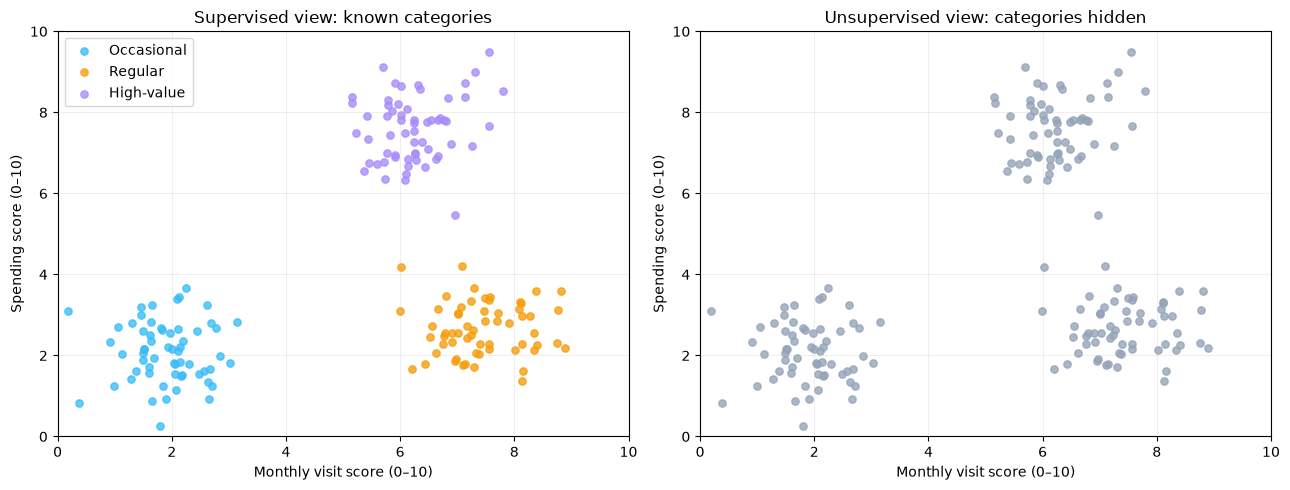

In [5]:
X_numpy = X.cpu().numpy()
y_numpy = y.cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_numpy == class_id
    axes[0].scatter(
        X_numpy[mask, 0], X_numpy[mask, 1],
        s=28, alpha=0.78, color=CLASS_COLORS[class_id], label=class_name
    )
axes[0].set_title("Supervised view: known categories")
axes[0].legend()

axes[1].scatter(
    X_numpy[:, 0], X_numpy[:, 1],
    s=28, alpha=0.78, color=NEUTRAL_COLOR
)
axes[1].set_title("Unsupervised view: categories hidden")

for ax in axes:
    ax.set_xlabel("Monthly visit score (0–10)")
    ax.set_ylabel("Spending score (0–10)")
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "same_data_labeled_vs_unlabeled.png", dpi=160, bbox_inches="tight")
plt.show()

### Pause and think

In the left plot, each observation has a known category. In the right plot, the category is not supplied.

- A supervised method can learn from the relationship between the numeric inputs and the known answers.
- An unsupervised method must look for structure in the numeric inputs without those answers.

The unsupervised problem is **not** “learn the hidden category.” It is “find groups or patterns using the information that is available.”

## 5. Supervised learning: learn from examples with known answers

In supervised learning, each training example comes with an input and a target answer. The model makes a prediction, compares it with the known answer, and uses the error signal to update its parameters.

For this demonstration, the task is **classification**: predict one of three customer categories.

Conceptually:

`customer scores + known category → train a classifier → predict a category for a new customer`

We are not studying the full dataset vocabulary or evaluation procedure here; those are covered in the next lessons.

## 6. Build a small supervised classifier in PyTorch

Our model has one linear layer with two input values and three output scores (one score for each category). These output scores are called **logits**. The largest logit gives the model's predicted category.

This is intentionally a small model so that the main learning idea remains visible.

In [6]:
class CustomerClassifier(nn.Module):
    """A tiny classifier: two input features mapped to three class scores."""

    def __init__(self):
        super().__init__()
        self.output_layer = nn.Linear(in_features=2, out_features=3)

    def forward(self, features):
        return self.output_layer(features)


supervised_model = CustomerClassifier().to(device)

# The model returns three raw scores (logits) for each customer.
example_logits = supervised_model(X[:5])
print("Output shape for five customers:", tuple(example_logits.shape))
print("First customer's logits:", example_logits[0].detach().numpy())

Output shape for five customers: (5, 3)
First customer's logits: [ 0.06180811  2.7405593  -0.42723304]


### 6.1 Define the loss function and optimizer

- `CrossEntropyLoss` compares the model's class scores with the known category IDs.
- `SGD` updates the model's learnable weights and biases using gradients.

Notice that we pass raw logits to `CrossEntropyLoss`. We do not apply `softmax` before calculating this loss; PyTorch handles the required calculation internally.

In [7]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(supervised_model.parameters(), lr=0.04)

number_of_epochs = 350
supervised_loss_history = []

for epoch in range(number_of_epochs):
    # 1. Clear gradients left from the previous update.
    optimizer.zero_grad()

    # 2. Forward pass: calculate class scores from the input features.
    logits = supervised_model(X)

    # 3. Compare predictions with the known category labels.
    loss = loss_function(logits, y)

    # 4. Backward pass: calculate gradients for the model parameters.
    loss.backward()

    # 5. Update the model parameters.
    optimizer.step()

    supervised_loss_history.append(float(loss.item()))

    if (epoch + 1) % 70 == 0:
        print(f"Epoch {epoch + 1:>3}/{number_of_epochs} | loss: {loss.item():.4f}")

print("\nTraining loop complete.")

Epoch  70/350 | loss: 0.4914
Epoch 140/350 | loss: 0.3669
Epoch 210/350 | loss: 0.2937
Epoch 280/350 | loss: 0.2436
Epoch 350/350 | loss: 0.2073

Training loop complete.


### 6.2 Observe the training process

The chart shows the loss on the same examples used for training. A decreasing curve indicates that the model is fitting these known examples better. This is a teaching demonstration, **not** a measurement of performance on unseen data. We will learn proper data splitting and generalization later.

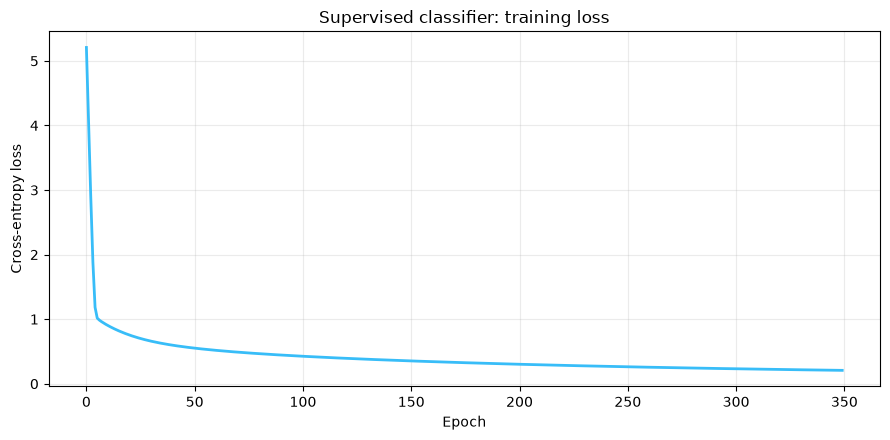

First training loss: 5.2077
Final training loss: 0.2073


In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(supervised_loss_history, linewidth=2, color="#38BDF8")
ax.set_title("Supervised classifier: training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "supervised_training_loss.png", dpi=160, bbox_inches="tight")
plt.show()

print(f"First training loss: {supervised_loss_history[0]:.4f}")
print(f"Final training loss: {supervised_loss_history[-1]:.4f}")

### 6.3 See the model's learned classification regions

The background color shows which category the model predicts at each location in the two-feature space. The points show the supplied labeled examples.

This visualization helps answer: “What decision rule did the classifier learn from the labeled examples?”

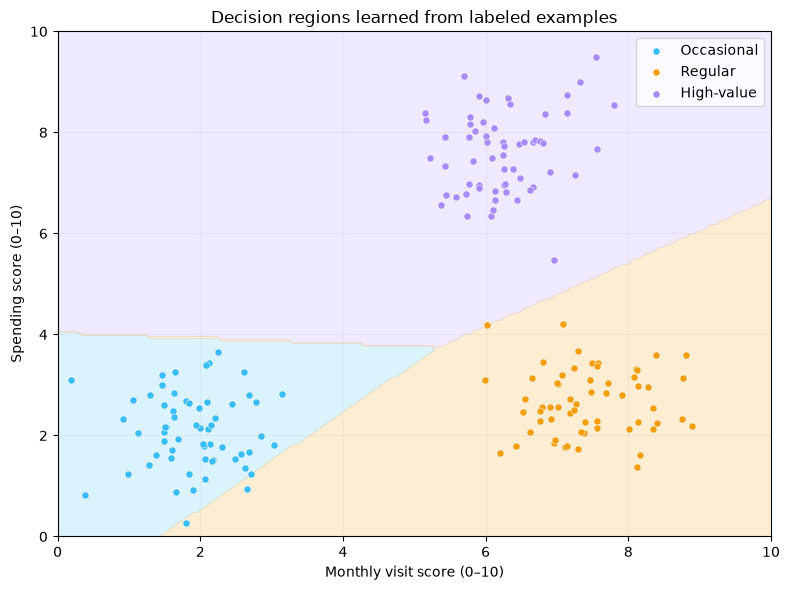

In [9]:
# Build a grid of possible customer feature combinations.
visit_axis = np.linspace(0, 10, 180)
spend_axis = np.linspace(0, 10, 180)
xx, yy = np.meshgrid(visit_axis, spend_axis)
grid_points = torch.tensor(
    np.column_stack([xx.ravel(), yy.ravel()]), dtype=torch.float32, device=device
)

with torch.no_grad():
    grid_predictions = supervised_model(grid_points).argmax(dim=1).cpu().numpy()

class_map = grid_predictions.reshape(xx.shape)
from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(
    xx, yy, class_map,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=CLASS_COLORS,
    alpha=0.18,
)
for class_id, class_name in enumerate(CLASS_NAMES):
    mask = y_numpy == class_id
    ax.scatter(
        X_numpy[mask, 0], X_numpy[mask, 1],
        s=26, color=CLASS_COLORS[class_id], edgecolor="white",
        linewidth=0.35, label=class_name
    )
ax.set_title("Decision regions learned from labeled examples")
ax.set_xlabel("Monthly visit score (0–10)")
ax.set_ylabel("Spending score (0–10)")
ax.legend()
ax.grid(alpha=0.15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "supervised_decision_regions.png", dpi=160, bbox_inches="tight")
plt.show()

### 6.4 Use the classifier on new customers

After training, we can pass a new customer's two scores to the model. The model returns scores, which we convert to probabilities for a more readable demonstration.

In [10]:
def predict_customer_categories(model, new_features):
    """Return the predicted category and class probabilities for new rows."""
    model.eval()
    with torch.no_grad():
        logits = model(new_features.to(device))
        probabilities = torch.softmax(logits, dim=1)
        predicted_ids = probabilities.argmax(dim=1)
    return predicted_ids, probabilities

new_customers = torch.tensor(
    [
        [2.5, 2.0],
        [7.2, 2.8],
        [6.0, 7.8],
    ],
    dtype=torch.float32,
)

predicted_ids, probabilities = predict_customer_categories(
    supervised_model, new_customers
)

supervised_predictions = []
for features, predicted_id, probability_row in zip(
    new_customers, predicted_ids, probabilities
):
    predicted_name = CLASS_NAMES[int(predicted_id)]
    confidence = float(probability_row[int(predicted_id)])
    supervised_predictions.append({
        "visit_score": float(features[0]),
        "spending_score": float(features[1]),
        "predicted_class_id": int(predicted_id),
        "predicted_class": predicted_name,
        "predicted_probability": confidence,
    })
    print(
        f"Visits={features[0]:.1f}, spending={features[1]:.1f} "
        f"→ {predicted_name} (model probability: {confidence:.1%})"
    )

Visits=2.5, spending=2.0 → Occasional (model probability: 62.8%)
Visits=7.2, spending=2.8 → Regular (model probability: 95.6%)
Visits=6.0, spending=7.8 → High-value (model probability: 92.5%)


## 7. Unsupervised learning: find patterns without supplied answers

Now we change the task.

We keep the same two numeric features, but the clustering algorithm will **not** receive `y`, the known category IDs. There is no target category for it to predict.

Instead, we ask it to group observations that are close to one another in the feature space.

One common unsupervised method is **K-means clustering**. We will implement its main steps with PyTorch:

1. Choose the number of clusters, `k`.
2. Start with `k` initial centroids.
3. Assign each observation to its nearest centroid.
4. Move each centroid to the mean of the observations assigned to it.
5. Repeat the assignment and update steps until the centroids stop moving much or we reach the iteration limit.

K-means does not know what “Occasional” or “High-value” means. It only works with the numeric features and distances.

> **PyTorch note:** K-means is not a neural network. It is an iterative clustering algorithm. In this lesson, PyTorch is used as a tensor library for calculating distances, assigning points, and updating centroids. This keeps the calculations in the same framework while making the unsupervised algorithm easy to inspect.

### 7.1 Give K-means only the feature tensor

We create a new variable containing only the two numeric columns. The clustering function below accepts this tensor—not the known category labels.

In [11]:
# IMPORTANT: no category labels are passed to K-means.
X_unlabeled = X.clone()
print("Unlabeled feature tensor shape:", tuple(X_unlabeled.shape))
print("The clustering input contains only the two numeric features.")

Unlabeled feature tensor shape: (180, 2)
The clustering input contains only the two numeric features.


### 7.2 Implement K-means using PyTorch tensor operations

This is a compact educational implementation. It shows the assignment and centroid-update steps explicitly. It includes a small safeguard for an empty cluster, which can occur when no point is assigned to a centroid.

In [12]:
def run_kmeans(features, n_clusters=3, max_iterations=50, seed=17, tolerance=1e-4):
    """Run a small, educational K-means implementation with PyTorch tensors.

    Args:
        features: Tensor with shape [number_of_samples, number_of_features].
        n_clusters: Number of groups requested by the user.
        max_iterations: Maximum assignment/update cycles.
        seed: Random seed used to choose initial centroids.
        tolerance: Stop when total centroid movement is smaller than this value.

    Returns:
        assignments: Cluster ID for each input row.
        centroids: Final cluster centers.
        centroid_history: Initial and updated centers for visualization.
    """
    if features.ndim != 2:
        raise ValueError("features must be a 2D tensor")
    if not 1 <= n_clusters <= features.shape[0]:
        raise ValueError("n_clusters must be between 1 and number of samples")

    generator = torch.Generator(device=features.device).manual_seed(seed)
    initial_indices = torch.randperm(
        features.shape[0], generator=generator, device=features.device
    )[:n_clusters]
    centroids = features[initial_indices].clone()
    centroid_history = [centroids.clone()]

    for _ in range(max_iterations):
        # Assignment step: every point joins its nearest centroid.
        distances = torch.cdist(features, centroids)
        assignments = distances.argmin(dim=1)

        # Update step: each centroid becomes the mean of its assigned points.
        updated_centroids = []
        for cluster_id in range(n_clusters):
            members = features[assignments == cluster_id]
            if members.shape[0] > 0:
                updated_centroids.append(members.mean(dim=0))
            else:
                # If a cluster is empty, keep its previous center for this cycle.
                updated_centroids.append(centroids[cluster_id].clone())

        new_centroids = torch.stack(updated_centroids)
        centroid_history.append(new_centroids.clone())
        movement = torch.linalg.vector_norm(new_centroids - centroids)
        centroids = new_centroids

        if movement.item() < tolerance:
            break

    # Recompute assignments using the final updated centroids.
    final_assignments = torch.cdist(features, centroids).argmin(dim=1)
    return final_assignments, centroids, centroid_history


cluster_ids, final_centroids, centroid_history = run_kmeans(
    X_unlabeled, n_clusters=3, max_iterations=50, seed=17
)

print(f"K-means iterations: {len(centroid_history) - 1}")
print("Final centroids:")
print(final_centroids)

K-means iterations: 5
Final centroids:
tensor([[6.2419, 7.5932],
        [1.9077, 2.0986],
        [7.4331, 2.6618]])


### 7.3 Visualize the groups discovered by K-means

Each color now represents a cluster assigned by K-means. These IDs are created by the algorithm. Cluster `0` is not inherently better, more important, or the same as category `0` from the supervised example.

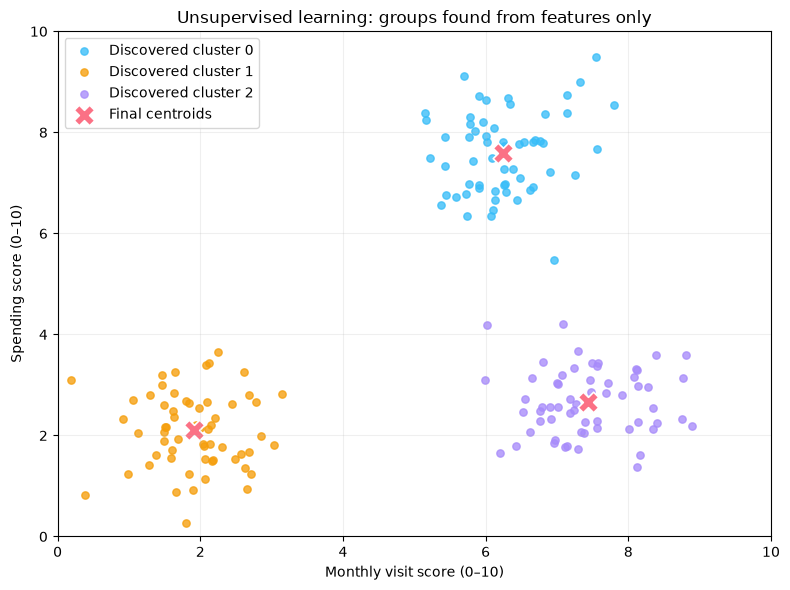

In [13]:
cluster_numpy = cluster_ids.cpu().numpy()
centroid_numpy = final_centroids.cpu().numpy()

fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(3):
    mask = cluster_numpy == cluster_id
    ax.scatter(
        X_numpy[mask, 0], X_numpy[mask, 1],
        s=28, alpha=0.78, color=CLASS_COLORS[cluster_id],
        label=f"Discovered cluster {cluster_id}"
    )
ax.scatter(
    centroid_numpy[:, 0], centroid_numpy[:, 1],
    marker="X", s=220, color="#FB7185", edgecolor="white",
    linewidth=1.2, label="Final centroids"
)
ax.set_title("Unsupervised learning: groups found from features only")
ax.set_xlabel("Monthly visit score (0–10)")
ax.set_ylabel("Spending score (0–10)")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "unsupervised_kmeans_clusters.png", dpi=160, bbox_inches="tight")
plt.show()

### 7.4 Watch the centroids move

A centroid is the center of a cluster. During K-means, the centroids move as assignments change. The following plot shows their positions after each update.

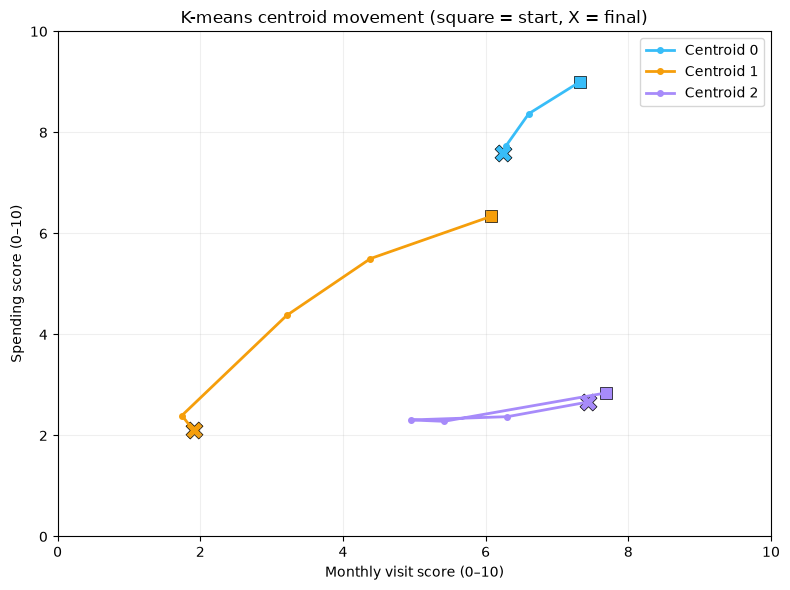

In [14]:
fig, ax = plt.subplots(figsize=(8, 6))
for cluster_id in range(3):
    path = torch.stack([step[cluster_id] for step in centroid_history]).cpu().numpy()
    ax.plot(path[:, 0], path[:, 1], marker="o", markersize=4,
            linewidth=2, color=CLASS_COLORS[cluster_id],
            label=f"Centroid {cluster_id}")
    ax.scatter(path[0, 0], path[0, 1], marker="s", s=70,
               color=CLASS_COLORS[cluster_id], edgecolor="black", linewidth=0.5)
    ax.scatter(path[-1, 0], path[-1, 1], marker="X", s=150,
               color=CLASS_COLORS[cluster_id], edgecolor="black", linewidth=0.5)
ax.set_title("K-means centroid movement (square = start, X = final)")
ax.set_xlabel("Monthly visit score (0–10)")
ax.set_ylabel("Spending score (0–10)")
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "kmeans_centroid_movement.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Compare the two learning approaches

| Question | Supervised learning | Unsupervised learning |
|---|---|---|
| Are target labels supplied? | Yes | No |
| What does the method learn? | A mapping from inputs to known targets | Structure or patterns in the inputs |
| This notebook's task | Predict a known customer category | Group similar customer activity patterns |
| Example method | Linear classifier | K-means clustering |
| Typical output | Predicted category | Cluster assignment |

**Important:** K-means requires us to choose `k`, the number of clusters. “Unsupervised” does not mean “no decisions or assumptions.” We still choose the features and algorithm settings. The algorithm simply does not receive the target categories used in supervised learning.

## 9. Common misconceptions

1. **“Unsupervised learning means there is no data.”** No. It uses data, but no target labels are supplied for the learning task.
2. **“A cluster ID is a real-world category.”** Not automatically. A cluster ID is just an identifier produced by an algorithm. A person must interpret whether the grouping is useful.
3. **“Supervised learning always predicts a category.”** No. It can also predict a number, as in house-price prediction. Category prediction is classification; number prediction is regression.
4. **“Unsupervised learning always discovers the correct groups.”** No. Results depend on the data, chosen features, algorithm, and settings such as `k`.
5. **“The two methods are competing versions of the same task.”** They answer different questions. The correct choice depends on whether the task has known target labels and what we want to discover or predict.

## 10. Mini challenge: change the number of clusters

Change `n_clusters` from `3` to `2` and then to `4`. Re-run the K-means cells and observe:

- how the discovered groups change;
- how many points are assigned to each cluster;
- how the centroid locations move;
- why the output depends on a choice made by the user.

For an extra challenge, compare the two supervised and unsupervised plots and explain why one can attach category names during training while the other cannot.

In [15]:
# Try changing this value to 2 or 4, then re-run the K-means cells above.
challenge_k = 4
challenge_ids, challenge_centroids, challenge_history = run_kmeans(
    X_unlabeled, n_clusters=challenge_k, max_iterations=50, seed=17
)

unique_ids, counts = torch.unique(challenge_ids, return_counts=True)
print(f"Requested clusters: {challenge_k}")
print("Number of points per discovered cluster:")
for cluster_id, count in zip(unique_ids.tolist(), counts.tolist()):
    print(f"  Cluster {cluster_id}: {count} points")

Requested clusters: 4
Number of points per discovered cluster:
  Cluster 0: 31 points
  Cluster 1: 29 points
  Cluster 2: 60 points
  Cluster 3: 60 points


## 11. Export the lesson results

The notebook is the source of truth for the data, supervised training curve, predicted categories, K-means assignments, and centroid movement. The Manim project reads these exported files; it does not train a second model.

In [16]:
# Export data in a form that the separate Manim project can read.
export_df = pd.DataFrame({
    "monthly_visit_score": X_numpy[:, 0],
    "spending_score": X_numpy[:, 1],
    "known_label_id": y_numpy,
    "known_label_name": [CLASS_NAMES[int(i)] for i in y_numpy],
    "cluster_id": cluster_numpy,
})
export_df.to_csv(OUTPUT_DIR / "customer_activity.csv", index=False)

centroid_rows = []
for step_index, centers_at_step in enumerate(centroid_history):
    for cluster_id, center in enumerate(centers_at_step.tolist()):
        centroid_rows.append({
            "step": step_index,
            "cluster_id": cluster_id,
            "monthly_visit_score": center[0],
            "spending_score": center[1],
        })
pd.DataFrame(centroid_rows).to_csv(
    OUTPUT_DIR / "kmeans_centroid_history.csv", index=False
)

cluster_counts = torch.bincount(cluster_ids, minlength=3).tolist()

# Store all values needed by the Manim scenes in one JSON file.
lesson_results = {
    "phase": 2,
    "module": "2.1 — ML Fundamentals",
    "lesson": "2.1.2",
    "title": "Understand Supervised vs. Unsupervised Learning",
    "dataset": {
        "sample_count": int(X.shape[0]),
        "feature_names": ["Monthly visit score", "Spending score"],
        "feature_min": 0.0,
        "feature_max": 10.0,
        "class_names": CLASS_NAMES,
        "points": [
            {
                "x": float(row[0]),
                "y": float(row[1]),
                "known_label_id": int(label),
                "cluster_id": int(cluster),
            }
            for row, label, cluster in zip(X_numpy, y_numpy, cluster_numpy)
        ],
    },
    "supervised": {
        "model": "nn.Linear(2, 3)",
        "loss_function": "nn.CrossEntropyLoss",
        "optimizer": "torch.optim.SGD",
        "epochs": number_of_epochs,
        "first_training_loss": supervised_loss_history[0],
        "final_training_loss": supervised_loss_history[-1],
        "training_accuracy": float(
            (supervised_model(X).argmax(dim=1) == y).float().mean().item()
        ),
        "loss_history": supervised_loss_history,
        "predictions": supervised_predictions,
    },
    "unsupervised": {
        "algorithm": "K-means implemented with PyTorch tensor operations",
        "k": 3,
        "iterations": len(centroid_history) - 1,
        "cluster_counts": [int(value) for value in cluster_counts],
        "final_centroids": final_centroids.tolist(),
        "centroid_history": [step.tolist() for step in centroid_history],
        "note": "K-means received X_unlabeled only; known category labels were not passed to it.",
    },
}

with (OUTPUT_DIR / "lesson_results.json").open("w", encoding="utf-8") as file:
    json.dump(lesson_results, file, indent=2)

print("Exported video-generation data to:", OUTPUT_DIR.resolve())
print("Files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path.name)

Exported video-generation data to: D:\AI\Assignment\machine-learning\module1\phase-2-lesson-2.1.2-supervised-vs-unsupervised-learning\notebooks\outputs
Files:
 - customer_activity.csv
 - kmeans_centroid_history.csv
 - kmeans_centroid_movement.png
 - lesson_results.json
 - same_data_labeled_vs_unlabeled.png
 - supervised_decision_regions.png
 - supervised_training_loss.png
 - unsupervised_kmeans_clusters.png


## 12. Recap

- **Supervised learning** uses examples with known target labels. A model learns to predict those targets. It can be used for classification (categories) and regression (numbers).
- **Unsupervised learning** uses examples without supplied target labels for the task. It looks for structure, such as groups of similar observations.
- In our supervised example, PyTorch learned to predict one of three known customer categories.
- In our unsupervised example, K-means grouped customers using only their two numeric scores.
- The cluster IDs are not meaningful names by themselves; interpreting clusters requires context.

### What comes next?

In **Lesson 2.1.3 — Features, Targets, Datasets, and Labels**, we will examine the data vocabulary more carefully and learn how to represent a dataset clearly before training a model.

### Final question

You have 5,000 customer records, but nobody has assigned customer categories. You want to discover groups with similar behavior. Which learning setup would you start with, and why?